## Step 1 — Setup: versions

In [5]:
import sys
print(sys.executable)


/Users/ibrakhimolzhabai/olzhabai_ML_task_1/.olzhabai_ML_task_1/bin/python


In [8]:
import sys, numpy, pandas, sklearn
print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:30:20) [Clang 20.1.8 ]
NumPy: 2.5.3
pandas: 3.0.6
scikit-learn: 1.9.1


In [10]:
print(df["listed_date"].sample(5).tolist())
print(df["rooms"].sample(10).tolist())
print(df["area_m2"].sample(10).tolist())
print(df["price_kzt"].sample(10).tolist())

['2026-01-11', '2026-03-23', '2026-06-26', '2026-06-19', '2026-08-14']
['1', '4', '2', '2', '4', '2', '3', '1', '1', '3']
['66.3 m²', '36.1', '122,5', '55.7', '61.1 m²', '78.1', '53.1', '50.4', '37.5', '59.8']
['52,760,000', '23880000', '124040000', '64280000', '113570000', '28920000', '34490000', '42 240 000 ₸', '167850000', '35720000']


## Step 2 — Load and inspect

In [9]:
import pandas as pd

YOUR_ID = 2586

raw = pd.read_csv("data/almaty_apartments_raw.csv")
ids = raw["listing_id"].drop_duplicates().sample(frac=0.9, random_state=YOUR_ID)
df = raw[raw["listing_id"].isin(ids)].reset_index(drop=True)

print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df.describe(include="all").T)

(1153, 11)
listing_id              str
listed_date             str
district                str
rooms                   str
area_m2                 str
floor                 int64
total_floors          int64
year_built          float64
building_type           str
ceiling_height_m    float64
price_kzt               str
dtype: object
listing_id            0
listed_date           0
district              0
rooms                 0
area_m2               0
floor                 0
total_floors          0
year_built           53
building_type         0
ceiling_height_m    137
price_kzt             0
dtype: int64
                   count unique         top freq         mean        std  min  \
listing_id          1153   1080   ALM-10003    3          NaN        NaN  NaN   
listed_date         1153    247  2026-04-18   12          NaN        NaN  NaN   
district            1153     48       Medeu  142          NaN        NaN  NaN   
rooms               1153      6           2  434          NaN     

1. Types.
listed_date, rooms, area_m2, and price_kzt have dtype object even though they should be a date and numbers. listed_date isn't parsed automatically because pd.read_csv doesn't infer dates by default - it needs parse_dates or an explicit conversion. rooms mixes numeric strings with the word "studio", which forces the whole column to be text. area_m2 mixes a unit suffix ("m²") with values that use a comma as a decimal separator (e.g. "122,5" instead of "122.5"). price_kzt mixes comma- and space-separated thousands with a currency symbol (₸), e.g. "52,760,000" and "42 240 000 ₸".

2. Grain.
One row of the cleaned table should represent one active apartment listing (listing_id). df.duplicated().sum() returns 32 — exact copies of another row, safe to drop. After removing exact duplicates, df.drop_duplicates()["listing_id"].duplicated().sum() returns 41 rows that share a listing_id with another row but are not identical — these are reposts. Looking at two such pairs (e.g. ALM-10003 and ALM-10938), the rows differ in listed_date and price_kzt: the same apartment was reposted later at a different (usually lower) price. This means the most recent posting by date is the valid one to keep.

3. Validation spec.

| Column | Expected type | Valid range |
|---|---|---|
| listing_id | string | unique per listing |
| listed_date | datetime | within dataset's time span (2026) |
| district | category | exactly 8 canonical names |
| rooms | int | 1–6 (studio → 1) |
| area_m2 | float | > 0, realistically 15–300 |
| floor | int | 1 to total_floors, not negative |
| total_floors | int | 1–30 |
| year_built | int | 1950–2026, not 0 |
| building_type | category | panel / brick / monolith |
| ceiling_height_m | float | 2.2–4.0, not 0 |
| price_kzt | float | > 0 |


## Step 3a — Duplicates and reposts

In [11]:
print(df.duplicated().sum())

exact_gone = df.drop_duplicates()
repost_count = exact_gone["listing_id"].duplicated().sum()
print(repost_count)

dup_ids = exact_gone[exact_gone["listing_id"].duplicated(keep=False)]["listing_id"].unique()[:2]
print(df[df["listing_id"].isin(dup_ids)].sort_values("listing_id"))

32
41
    listing_id listed_date district rooms area_m2  floor  total_floors  \
8    ALM-10003  2026-05-29   Auezov     2    48.6      2             5   
822  ALM-10003  2026-05-29   Auezov     2    48.6      2             5   
959  ALM-10003  2026-05-04   Auezov     2    48.6      2             5   
12   ALM-10938  2026-08-10    Medeu     5   133.0      1             9   
512  ALM-10938  2026-08-21    Medeu     5   133.0      1             9   

     year_built building_type  ceiling_height_m  price_kzt  
8        1978.0         panel              2.55   26120000  
822      1978.0         panel              2.55   26120000  
959      1978.0         panel              2.55   28320000  
12       2013.0      monolith              2.93  177470000  
512      2013.0      monolith              2.93  167850000  


In [12]:
print(df.shape)
df = df.drop_duplicates()

df["listed_date"] = pd.to_datetime(df["listed_date"])
df = df.sort_values("listed_date").drop_duplicates("listing_id", keep="last").reset_index(drop=True)
print(df.shape)

(1153, 11)
(1080, 11)


## Step 3c — Parsing rooms

In [13]:
df["rooms"] = df["rooms"].astype(str).str.strip().str.lower().replace({"studio": "1"})
df["rooms"] = pd.to_numeric(df["rooms"], errors="coerce")
print(df["rooms"].unique(), df["rooms"].isna().sum())


[3 2 4 1 5] 0


In [14]:
import numpy as np

df["area_m2"] = (df["area_m2"].astype(str).str.replace("m²","",regex=False)
                  .str.strip().str.replace(",",".",regex=False))
df["area_m2"] = pd.to_numeric(df["area_m2"], errors="coerce")

df["price_kzt"] = df["price_kzt"].astype(str).str.replace(r"[^\d]","",regex=True)
df["price_kzt"] = pd.to_numeric(df["price_kzt"], errors="coerce")

print(df["area_m2"].isna().sum(), df["price_kzt"].isna().sum())

0 0


## Step 3b — Fixing district categories

In [15]:
canon = ["Alatau","Almaly","Auezov","Bostandyk","Medeu","Nauryzbay","Turksib","Zhetysu"]
key = df["district"].astype(str).str.strip().str.lower()

def match_district(k):
    for c in canon:
        if c.lower()[:5] in k or k[:5] in c.lower():
            return c
    return np.nan

df["district"] = key.apply(match_district)
print(df["district"].nunique(), df["district"].isna().sum())

8 20


## Step 4 — Sentinels

In [16]:
sentinel_floor = (df["floor"] == -1).sum()
sentinel_year = (df["year_built"] == 0).sum()
sentinel_ceil = (df["ceiling_height_m"] == 0).sum()
print(sentinel_floor, sentinel_year, sentinel_ceil)

df["floor"] = df["floor"].replace(-1, np.nan)
df["year_built"] = df["year_built"].replace(0, np.nan)
df["ceiling_height_m"] = df["ceiling_height_m"].replace(0, np.nan)

11 22 19


## Step 4 — Impossible values

In [17]:
impossible = df["floor"] > df["total_floors"]
print(impossible.sum())
df.loc[impossible, "floor"] = np.nan

9


## Step 4 — Outliers and saving clean CSV

In [18]:
df["price_per_m2"] = df["price_kzt"] / df["area_m2"]
df["area_before_fix"] = df["area_m2"]

def fences(values, groups):
    q1 = groups.map(values.groupby(groups).quantile(0.25))
    q3 = groups.map(values.groupby(groups).quantile(0.75))
    iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr

low, high = fences(df["price_per_m2"], df["district"])
outliers = (df["price_per_m2"] < low) | (df["price_per_m2"] > high)
print(outliers.sum())

df.to_csv("data/almaty_apartments_clean.csv", index=False)
print("saved", df.shape)

13
saved (1080, 13)


## Step 5a — Train/test split

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

NUMERIC = ["rooms","area_m2","floor","total_floors","year_built","ceiling_height_m"]
YOUR_ID = 421

train, test = train_test_split(df, test_size=0.2, random_state=YOUR_ID)
train, test = train.copy(), test.copy()
print(train[NUMERIC].isna().sum())

rooms                 0
area_m2               0
floor                14
total_floors          0
year_built           62
ceiling_height_m    108
dtype: int64


## Step 5b — Diagnosing missingness mechanism

In [20]:
rate = train.assign(m=train["ceiling_height_m"].isna()).groupby("building_type")["m"].mean()
print(rate)

building_type
brick       0.135514
monolith    0.027778
panel       0.196133
Name: m, dtype: float64


## Step 5c — Masking experiment (MAE comparison)

In [21]:
known = train[train["ceiling_height_m"].notna()]
hidden = known.sample(frac=0.15, random_state=YOUR_ID).index
rest = train.drop(index=hidden)
answers = train.loc[hidden, "ceiling_height_m"]

gm = rest["ceiling_height_m"].median()
mae_global = mean_absolute_error(answers, pd.Series(gm, index=hidden))

grp = rest.groupby("building_type")["ceiling_height_m"].median()
mae_group = mean_absolute_error(answers, train.loc[hidden,"building_type"].map(grp))
print("MAE global:", mae_global, "MAE group:", mae_group)

MAE global: 0.1492920353982301 MAE group: 0.07955752212389386


## Step 5d — Filling missing values

In [22]:
med_ceil = train.groupby("building_type")["ceiling_height_m"].median()
med_year = train["year_built"].median()
med_floor = train["floor"].median()
for f in (train, test):
    f["ceiling_height_m"] = f["ceiling_height_m"].fillna(f["building_type"].map(med_ceil))
    f["year_built"] = f["year_built"].fillna(med_year)
    f["floor"] = f["floor"].fillna(med_floor)

print(train[NUMERIC].isna().sum().sum(), test[NUMERIC].isna().sum().sum())

0 0


## Step 6 — Scaling, encoding, final matrix

In [23]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression

CATEGORICAL = ["district","building_type"]
pre = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])
X_train = pre.fit_transform(train[NUMERIC+CATEGORICAL])
X_test = pre.transform(test[NUMERIC+CATEGORICAL])
model = LinearRegression().fit(X_train, train["price_kzt"])
print(X_train.shape, X_test.shape)
print("R2:", model.score(X_test, test["price_kzt"]))

(864, 18) (216, 18)
R2: 0.8662008664263129


## Step 7 — EDA plot and cleaning log

Matplotlib is building the font cache; this may take a moment.


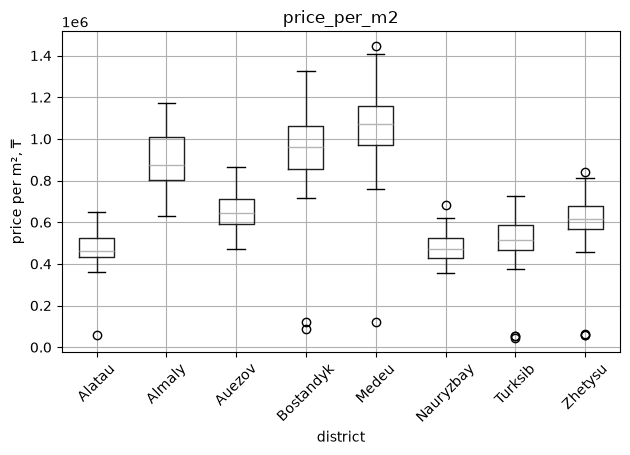

In [24]:
import matplotlib.pyplot as plt
df.boxplot(column="price_per_m2", by="district", rot=45)
plt.ylabel("price per m², ₸")
plt.suptitle("")
plt.tight_layout()
plt.show()

df.to_csv("data/almaty_apartments_clean.csv", index=False)